# Differential Evolution (DE) untuk Optimasi Alokasi Dana Saham LQ45

**Apa itu Differential Evolution?** DE adalah metode optimasi berbasis populasi. DE membuat sejumlah kandidat solusi, lalu memperbaikinya melalui tiga proses utama: **mutasi → crossover → seleksi**. Di proyek ini, vektor DE diterjemahkan menjadi pembelian lot saham menggunakan `decoder.py`; kelayakan dan kualitasnya diperiksa menggunakan aturan bersama di `fitness.py`.

### Alur Eksperimen

1. **Memuat data saham** dan membentuk persoalan optimasi (42 saham, harga lot, return, risiko).
2. **Mengecek decoder dan fitness**, agar kandidat DE menjadi alokasi yang memenuhi aturan.
3. **Menjalankan DE berkali-kali** untuk batas maksimum jumlah saham $K=2,3,5,7,10$.
4. **Memilih hasil terbaik yang layak** dari percobaan pada setiap nilai $K$.
5. **Menampilkan alokasi dana nyata**: saham, lot, biaya beli, bobot, dan kas tersisa.
6. **Menguji portofolio pada data di luar pelatihan** (*out-of-sample*).
7. **Menguji konsistensi pada tiga jendela waktu** (*walk-forward*)

## 1. Setup dan Parameter
**Tujuan:** menyiapkan pustaka dan menghubungkan notebook dengan modul proyek bersama. Angka modal, ukuran lot, batas K, tingkat bebas risiko, dan anggaran evaluasi dibaca dari `config.py`.

**Output:** lokasi proyek, modul DE yang digunakan, dan parameter utama.

In [53]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "config.py").exists(), "Buka folder proyek atau jalankan notebook dari folder notebooks/"
for p in (str(ROOT), str(ROOT / 'src')):
    if p not in sys.path: sys.path.insert(0, p)
import config
from algorithms import de
from data import muat_jendela, buat_problem
from decoder import decode
from evaluasi import nilai_uji, metrik_uji
print('Root:', ROOT)
print('DE module:', de.__file__)
print('Anggaran:', config.BUDGET_EVAL, 'evaluasi; Kardinalitas:', config.K_LIST)
from algorithms.brute_force_k2 import brute_force_k2
from evaluasi import analisis, rincian_kas, komponen_akhir, nilai_kas, nilai_1n, rp
from IPython.display import display
print('Jumlah jendela tersedia:', config.N_JENDELA)
print('Dana utama:', rp(config.D_UTAMA), '| Lot:', config.LOT_SIZE,
      '| rf tahunan:', f'{config.RISK_FREE:.0%}')

Root: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham
DE module: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\src\algorithms\de.py
Anggaran: 20000 evaluasi; Kardinalitas: [2, 3, 5, 7, 10]
Jumlah jendela tersedia: 5
Dana utama: Rp 5.000.000 | Lot: 100 | rf tahunan: 5%


In [54]:
# Agar tabel rapi
from IPython.display import display, Markdown

def tabel_rapi(data, persen=None, rupiah=None, desimal=None, bilangan=None, judul=None):
    """Format DataFrame dengan nama kolom deskriptif dan satuan eksplisit."""
    if judul:
        display(Markdown(f"**{judul}**"))
    df0 = pd.DataFrame(data).reset_index(drop=True)
    fmt = {}
    for col in (persen or []):
        if col in df0.columns: fmt[col] = lambda x: '—' if pd.isna(x) else f'{x:.2%}'
    for col in (rupiah or []):
        if col in df0.columns: fmt[col] = lambda x: '—' if pd.isna(x) else 'Rp ' + f'{x:,.0f}'.replace(',', '.')
    for col in (desimal or []):
        if col in df0.columns: fmt[col] = lambda x: '—' if pd.isna(x) else f'{x:,.3f}'.replace(',', '.')
    for col in (bilangan or []):
        if col in df0.columns: fmt[col] = lambda x: '—' if pd.isna(x) else f'{int(x)}'
    display(df0.style.format(fmt, na_rep='—').hide(axis='index'))

print('Format tabel siap: Rupiah, persen, dan satuan kolom akan ditampilkan secara konsisten.')

Format tabel siap: Rupiah, persen, dan satuan kolom akan ditampilkan secara konsisten.


## 2. Formulasi Masalah dan Batasan

**Tujuan:** menjelaskan apa yang dimaksimalkan DE dan aturan apa yang tidak boleh dilanggar. Nilai saham dinyatakan sebagai pembelian **lot bulat**, bukan bobot pecahan yang bebas dibeli.

Untuk bobot aktual saham:
$$
w_i = \frac{n_i c_i}{D}
$$
dengan:
- $n_i$: jumlah lot saham ke-$i$.
- $c_i$: biaya pembelian satu lot saham ke-$i$.
- $D$: total modal investasi.

**Fungsi objektif — memaksimalkan expected return:**
$$
\max R = \sum_{i=1}^{N} w_i \mu_i + w_{\text{kas}}r_f
$$

**Batas risiko portofolio:**
$$
\sigma_p = \sqrt{\mathbf{w}^{T}\Sigma\mathbf{w}} \leq \sigma_{\max}
$$
dengan:
$$
\sigma_{\max}=1{,}5\,\sigma_{1/N}
$$

**Batas kardinalitas:**
$$
\sum_{i=1}^{N}\mathbb{I}(n_i>0)\leq K
$$
Jumlah saham yang dipilih maksimal $K$, bukan harus tepat $K$.

**Batas modal:**
$$
\sum_{i=1}^{N}n_i c_i\leq D
$$
Sisa modal diperbolehkan menjadi kas.

**Batas bobot saham:**
$$
w_i \leq 0{,}20
$$
Batas bobot 20% berlaku untuk $K=7$ dan $K=10$.

**Representasi kromosom:** Setiap kandidat solusi direpresentasikan menggunakan $2N+1$ gen yang kemudian diproses oleh `decoder.py` menjadi jumlah lot, bobot aktual, dan kas.

**Aturan Deb:** solusi memenuhi kendala didahulukan; bila sama-sama layak, dipilih yang return-nya lebih tinggi. Risiko pada data uji tidak dibatasi saat optimasi.


## 3. Data Saham dan Pembentukan Problem

**Tujuan:** memuat harga lot, estimasi return dan kovarians dari **data latih**, lalu memastikan data uji berada setelah data latih.

**Output:** periode latih/uji, jumlah saham, batas risiko, dan **cuplikan 12 saham pertama**. Tabel cuplikan hanya data masukan, **belum** keputusan saham yang dipilih DE.

In [55]:
nama_data='kasus_tetap'
wdata=muat_jendela(nama_data)
P=buat_problem(wdata,K=5)
print('Rentang latih:',wdata['tanggal_latih_awal'],'s.d.',wdata['tanggal_latih_akhir'])
print('Rentang uji  :',wdata['tanggal_uji_awal'],'s.d.',wdata['tanggal_uji_akhir'])
print('N saham:',P.n,'| Gen:',P.n_genes,'| K:',P.K,'| Modal:',rp(P.D))
print('Sigma maksimum:',f'{P.sigma_max:.2%}','| Batas bobot per saham:',f'{P.cap:.0%}')
assert P.n_genes == 2*P.n+1
assert P.cov.shape==(P.n,P.n)
assert wdata['return_uji'].shape[1]==P.n
assert wdata['tanggal_latih_akhir'] < wdata['tanggal_uji_awal']
assert (P.harga_lot>0).all()
cuplikan = pd.DataFrame({'Saham':P.tickers,'Harga per Lot (Rp)':P.harga_lot,
                         'Expected Return Latih (%/Tahun)':P.mu,'Volatilitas Saham Latih (%/Tahun)':P.vol}).head(12)
tabel_rapi(cuplikan, persen=['Expected Return Latih (%/Tahun)','Volatilitas Saham Latih (%/Tahun)'],
           rupiah=['Harga per Lot (Rp)'], judul='Cuplikan Data Input: 12 Saham Pertama')

Rentang latih: 2021-11-23 s.d. 2025-09-30
Rentang uji  : 2025-10-01 s.d. 2026-09-30
N saham: 42 | Gen: 85 | K: 5 | Modal: Rp 5.000.000
Sigma maksimum: 23.90% | Batas bobot per saham: 100%


**Cuplikan Data Input: 12 Saham Pertama**

Saham,Harga per Lot (Rp),Expected Return Latih (%/Tahun),Volatilitas Saham Latih (%/Tahun)
ACES,Rp 43.000,-17.42%,43.46%
ADRO,Rp 169.000,38.56%,43.78%
AKRA,Rp 121.000,26.52%,40.36%
AMRT,Rp 193.000,19.27%,38.67%
ANTM,Rp 316.000,22.01%,42.83%
ARTO,Rp 213.000,-33.81%,64.64%
ASII,Rp 577.500,10.23%,26.83%
BBCA,Rp 762.500,5.88%,22.62%
BBNI,Rp 410.000,13.34%,29.79%
BBRI,Rp 390.000,8.09%,28.49%


## 4. Validasi Decoder, Fitness, dan Kelayakan

**Tujuan:** memeriksa apakah DE dan modul bersama mengubah kandidat menjadi jumlah lot bulat, mematuhi batas modal, maksimal K saham, batas bobot, dan menghasilkan evaluasi yang konsisten.

**Output:** status **LAYAK**, expected return, volatilitas latih, batas volatilitas, jumlah saham, dan persentase kas. Ini merupakan **uji fungsi singkat**.

In [56]:
from fitness import hitung
from decoder import decode_batch
uji=de.run(P,budget=1000,seed=0)
lots,bobot,kas=decode(uji.x,P)
r,s,v=hitung(lots[None,:],bobot[None,:],np.array([kas]),P)
assert uji.n_eval==1000
assert np.array_equal(lots,uji.lots)
assert np.all(lots>=0) and np.issubdtype(lots.dtype,np.integer)
assert (lots>0).sum()<=P.K
assert (lots*P.harga_lot).sum()<=P.D+1e-6
assert np.all(bobot<=P.cap+1e-9)
assert abs(bobot.sum()+kas-1)<1e-9
assert np.isclose(r[0],uji.R) and np.isclose(s[0],uji.sigma)
assert np.isclose(v[0],uji.viol)
assert uji.feasible
print(f'VALID | R={uji.R:.2%} | risiko={uji.sigma:.2%} / batas={P.sigma_max:.2%} | saham={(lots>0).sum()} | kas={kas:.1%}')

VALID | R=28.63% | risiko=23.80% / batas=23.90% | saham=4 | kas=27.7%


## 5. Cara Kerja Differential Evolution

**Tujuan:** menjelaskan mekanisme DE, implementasi aslinya berada di `src/algorithms/de.py`.

DE merepresentasikan satu kandidat alokasi sebagai vektor kontinu:
$$
\mathbf{x}\in[0,1]^{2N+1}
$$

Dengan $N=42$ saham, vektor berisi **85 gen**. Decoder menerjemahkannya menjadi pemilihan saham, jumlah lot, dan kas.

**Alur satu iterasi:**
1. **Mutasi:** pilih tiga individu berbeda lalu bentuk kandidat mutan.

   $$\mathbf{v}=\mathbf{x}_a+F(\mathbf{x}_b-\mathbf{x}_c)$$

2. **Pembatasan nilai:** komponen mutan dijaga pada interval $[0,1]$.
3. **Crossover binomial:** gabungkan gen vektor target dan mutan; setidaknya satu gen berasal dari mutan.
4. **Seleksi:** kandidat yang lebih baik dipilih berdasarkan prioritas kelayakan (aturan Deb). Kandidat yang melanggar batas risiko tidak otomatis mengungguli solusi layak hanya karena return-nya tinggi.
5. **Berulang** sampai anggaran evaluasi tercapai.

**Parameter:** ukuran populasi, faktor mutasi $F$, dan probabilitas crossover $CR$ ditampilkan langsung dari `de.DE_PARAM` pada sel berikutnya. Penjelasan parameter ini bukan bukti bahwa nilainya paling optimal.

In [57]:
print('Parameter DE:',de.DE_PARAM)
print('Anggaran utama:',config.BUDGET_EVAL)
# Lihat sumber algoritma secara langsung di src/algorithms/de.py

Parameter DE: {'pop': 100, 'F': 0.5, 'CR': 0.9, 'n_seed': 0}
Anggaran utama: 20000


## 6. Pembanding Brute Force K=2

**Tujuan:** membandingkan kualitas solusi DE dengan pencarian menyeluruh pada persoalan K=2 yang menggunakan batasan masalah yang sama.

**Output:** return terbaik dari brute force, return DE, dan selisih keduanya dalam **poin persentase**. Selisih kecil memberi indikasi kualitas optimasi, bukan jaminan performa di pasar.

> Pemeriksaan ini **opsional** karena enumerasi bisa lebih berat. Nilai `JALANKAN_BRUTE_FORCE` dapat diubah pada sel berikutnya.

In [58]:
JALANKAN_BRUTE_FORCE = True  # ubah ke True jika ingin validasi tambahan
if JALANKAN_BRUTE_FORCE:
    P2=buat_problem(wdata,K=2)
    t0=time.perf_counter()
    acuan=brute_force_k2(P2)['kas bebas']
    de2=de.run(P2,budget=config.BUDGET_EVAL,seed=0)
    gap=max(0.0,acuan[0]-de2.R)
    print('Optimum brute-force:',f'{acuan[0]:.4%}')
    print('Return DE:',f'{de2.R:.4%}','| Gap absolut:',f'{gap:.4%}')
    print('Waktu brute force:',round(time.perf_counter()-t0,2),'detik (termasuk DE)')
else:
    print('Brute force dilewati. Untuk validasi opsional, set JALANKAN_BRUTE_FORCE=True.')

Optimum brute-force: 29.6576%
Return DE: 29.6269% | Gap absolut: 0.0308%
Waktu brute force: 0.57 detik (termasuk DE)


## 7. Eksperimen Utama (Kasus Tetap)

**Tujuan:** menjalankan DE pada **satu periode pelatihan/pengujian** dengan lima batas jumlah saham: K=2, 3, 5, 7, dan 10. Setiap K diulang 30 kali dengan seed berbeda, masing-masing menggunakan anggaran evaluasi yang sama.

**Output:** tabel **ringkasan per K** berisi jumlah percobaan, median expected return latih, variasi hasil, persentase run layak, waktu komputasi, kas, dan median return tahunan uji.

**Cara membaca:** median menunjukkan hasil tengah dari 30 seed; hasil terbaik untuk alokasi nyata ditampilkan nanti pada **Bagian 9**. Semua return dan risiko dinyatakan dalam **persen tahunan**, kecuali dinyatakan lain.

In [73]:
N_SEED_TETAP=30
KS_TETAP=[2,3,5,7,10]
BUDGET_TETAP=config.BUDGET_EVAL
hasil_tetap=[]; kandidat_tetap={}; histori_tetap={}
t0=time.perf_counter()
for K in KS_TETAP:
    pk=buat_problem(wdata,K=K)
    for seed in range(N_SEED_TETAP):
        result=de.run(pk,budget=BUDGET_TETAP,seed=seed)
        nilai=nilai_uji(pk,result.lots,wdata['return_uji'])
        m=metrik_uji(nilai,pk.D)
        hasil_tetap.append(dict(K=K,seed=seed,return_latih=result.R,risiko_latih=result.sigma,
                                valid_latih=result.feasible,waktu_detik=result.seconds,
                                eval_terbaik=result.n_eval_best,n_eval=result.n_eval,
                                saham_aktual=int((result.lots>0).sum()),
                                kas=(pk.D-(result.lots*pk.harga_lot).sum())/pk.D,
                                return_uji=m['setara_tahun'],risiko_uji=m['vol'],max_drawdown=m['mdd']))
        kandidat_tetap[(K,seed)]=(pk,result)
        histori_tetap[(K,seed)]=result.history
    print(f'K={K}: {N_SEED_TETAP} seed selesai')
df_tetap=pd.DataFrame(hasil_tetap)
print('Total run:',len(df_tetap),'| Waktu proses:',round(time.perf_counter()-t0,2),'detik')
ringkasan_tetap = df_tetap.groupby('K').agg(
    **{'Jumlah Run':('seed','count'), 'Median Return Latih (%/Tahun)':('return_latih','median'),
       'Simpangan Baku Return Latih (Poin Persentase)':('return_latih','std'),
       'Kelayakan Latih (% Run)':('valid_latih','mean'),
       'Median Waktu (Detik)':('waktu_detik','median'), 'Median Kas (% Modal)':('kas','median'),
       'Median Return Uji (%/Tahun)':('return_uji','median')}).reset_index()
tabel_rapi(ringkasan_tetap,
    persen=['Median Return Latih (%/Tahun)','Simpangan Baku Return Latih (Poin Persentase)',
            'Kelayakan Latih (% Run)','Median Kas (% Modal)','Median Return Uji (%/Tahun)'],
    desimal=['Median Waktu (Detik)'], judul='Ringkasan Hasil DE: Kasus Tetap, 30 Seed Per K')
# Ekspor kasus tetap secara terpisah dari hasil walk-forward
outdir=ROOT/"hasil"/"csv"; outdir.mkdir(parents=True,exist_ok=True)
df_tetap.to_csv(outdir/"de_kasus_tetap_30seed.csv",index=False)

K=2: 30 seed selesai
K=3: 30 seed selesai
K=5: 30 seed selesai
K=7: 30 seed selesai
K=10: 30 seed selesai
Total run: 150 | Waktu proses: 59.8 detik


**Ringkasan Hasil DE: Kasus Tetap, 30 Seed Per K**

K,Jumlah Run,Median Return Latih (%/Tahun),Simpangan Baku Return Latih (Poin Persentase),Kelayakan Latih (% Run),Median Waktu (Detik),Median Kas (% Modal),Median Return Uji (%/Tahun)
2,30,28.17%,0.56%,100.00%,0.335,33.52%,0.72%
3,30,29.74%,0.51%,100.00%,0.338,20.77%,-3.19%
5,30,31.66%,0.40%,100.00%,0.342,7.58%,-14.83%
7,30,30.49%,0.33%,100.00%,0.442,5.40%,14.02%
10,30,30.53%,0.31%,100.00%,0.419,5.10%,14.09%


## 8. Grafik Konvergensi dan Kestabilan

**Tujuan:** mengecek apakah pencarian DE semakin baik seiring evaluasi, dan seberapa konsisten hasil dari seed yang berbeda.

**Grafik 1 — Konvergensi:** sumbu X jumlah evaluasi fitness; sumbu Y expected return terbaik yang layak pada **data latih**, ditampilkan dalam persen.

**Grafik 2 — Boxplot:** sebaran expected return latih dari 30 seed untuk setiap nilai K. Kotak yang lebih sempit berarti hasil antar-seed lebih konsisten.

> Grafik ini menjelaskan **proses dan kestabilan optimasi**.

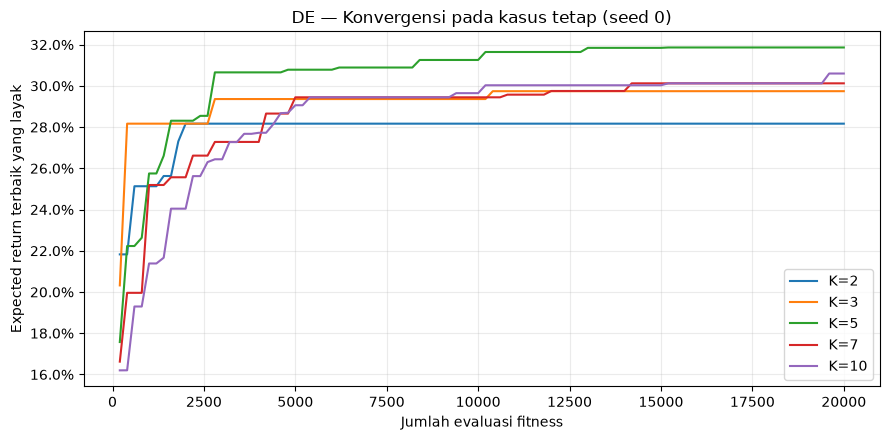

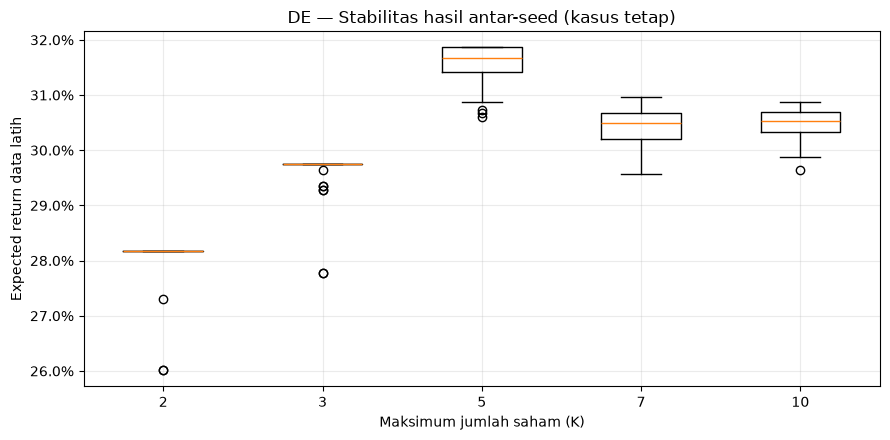

In [74]:
fig,ax=plt.subplots(figsize=(9,4.5))
for K in KS_TETAP:
    h=np.asarray(histori_tetap[(K,0)],dtype=float)
    ax.plot(h[:,0],h[:,1],label=f'K={K}')
ax.set(xlabel='Jumlah evaluasi fitness',ylabel='Expected return terbaik yang layak',title='DE — Konvergensi pada kasus tetap (seed 0)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
ax.boxplot([df_tetap.loc[df_tetap.K==k,'return_latih'].values for k in KS_TETAP],tick_labels=[str(k) for k in KS_TETAP])
ax.set(xlabel='Maksimum jumlah saham (K)',ylabel='Expected return data latih',title='DE — Stabilitas hasil antar-seed (kasus tetap)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.grid(alpha=.25);plt.tight_layout();plt.show()

## 9. Alokasi Saham, Jumlah Lot, dan Sisa Kas

Setelah mencoba 30 seed pada masing-masing K, notebook memilih **solusi dengan expected return latih tertinggi yang memenuhi kendala** pada tiap nilai K.

Bagian ini menghasilkan tiga tabel:

1. **Ringkasan alokasi terbaik per K:** seed terpilih, jumlah saham aktual, dana untuk saham, kas tersisa, expected return tahunan, dan risiko tahunan.
2. **Rincian pembelian untuk setiap K:** ticker saham, lot, harga per lot (Rp), biaya beli (Rp), bobot terhadap modal (%), dan kontribusi return tahunan (poin persentase).
3. **Rekonsiliasi modal:** biaya seluruh saham + kas = **Rp5.000.000** (atau modal dalam konfigurasi jika berubah).

**Penting:** "Terbaik" di sini berarti return *yang diperkirakan berdasarkan data latih*, **bukan** jaminan alokasi itu memberikan keuntungan tertinggi di data uji.

**Ringkasan Alokasi Terbaik untuk Setiap K**

K Maksimal,Seed Terbaik,Saham Dibeli (Emiten),Modal (Rp),Dana Saham (Rp),Sisa Kas (Rp),Kas (% Modal),Expected Return Latih (%/Tahun),Risiko Latih (%/Tahun),Batas Risiko (%/Tahun),Status
2,0,2,Rp 5.000.000,Rp 3.324.000,Rp 1.676.000,33.52%,28.17%,19.52%,19.62%,LAYAK
3,0,3,Rp 5.000.000,Rp 3.961.500,Rp 1.038.500,20.77%,29.74%,19.52%,19.62%,LAYAK
5,0,5,Rp 5.000.000,Rp 4.621.000,Rp 379.000,7.58%,31.86%,19.53%,19.62%,LAYAK
7,10,6,Rp 5.000.000,Rp 4.863.500,Rp 136.500,2.73%,30.96%,19.44%,19.62%,LAYAK
10,6,6,Rp 5.000.000,Rp 4.838.000,Rp 162.000,3.24%,30.87%,19.34%,19.62%,LAYAK


**Rincian Saham dan Lot, K=2 (Seed 0)**

Saham,Jumlah Lot,Harga per Lot (Rp),Biaya Beli (Rp),Bobot (% Modal),Estimasi Return Saham (%/Tahun),Kontribusi Return (Poin Persentase/Tahun)
BRIS,7,Rp 270.000,Rp 1.890.000,37.80%,45.33%,17.13%
ISAT,6,Rp 239.000,Rp 1.434.000,28.68%,32.62%,9.36%


Ringkasan Modal K=2: dana saham Rp 3.324.000 + kas Rp 1.676.000 = Rp 5.000.000
Expected return latih 28.17% per tahun | Risiko latih 19.52% | Jumlah saham 2 dari maksimum 2



...

Saham,Jumlah Lot,Harga per Lot (Rp),Biaya Beli (Rp),Bobot (% Modal),Estimasi Return Saham (%/Tahun),Kontribusi Return (Poin Persentase/Tahun)
ISAT,4,Rp 239.000,Rp 956.000,19.12%,32.62%,6.24%
ADRO,4,Rp 234.000,Rp 936.000,18.72%,25.72%,4.81%
JPFA,5,Rp 181.500,Rp 907.500,18.15%,25.68%,4.66%
ACES,12,Rp 72.000,Rp 864.000,17.28%,31.70%,5.48%
BRIS,3,Rp 270.000,Rp 810.000,16.20%,45.33%,7.34%
BRPT,4,Rp 97.500,Rp 390.000,7.80%,29.42%,2.29%


Ringkasan Modal K=7: dana saham Rp 4.863.500 + kas Rp 136.500 = Rp 5.000.000
Expected return latih 30.96% per tahun | Risiko latih 19.44% | Jumlah saham 6 dari maksimum 7



**Rincian Saham dan Lot, K=10 (Seed 6)**

Saham,Jumlah Lot,Harga per Lot (Rp),Biaya Beli (Rp),Bobot (% Modal),Estimasi Return Saham (%/Tahun),Kontribusi Return (Poin Persentase/Tahun)
ISAT,4,Rp 239.000,Rp 956.000,19.12%,32.62%,6.24%
ACES,13,Rp 72.000,Rp 936.000,18.72%,31.70%,5.93%
ADRO,4,Rp 234.000,Rp 936.000,18.72%,25.72%,4.81%
JPFA,5,Rp 181.500,Rp 907.500,18.15%,25.68%,4.66%
BRIS,3,Rp 270.000,Rp 810.000,16.20%,45.33%,7.34%
BRPT,3,Rp 97.500,Rp 292.500,5.85%,29.42%,1.72%


Ringkasan Modal K=10: dana saham Rp 4.838.000 + kas Rp 162.000 = Rp 5.000.000
Expected return latih 30.87% per tahun | Risiko latih 19.34% | Jumlah saham 6 dari maksimum 10



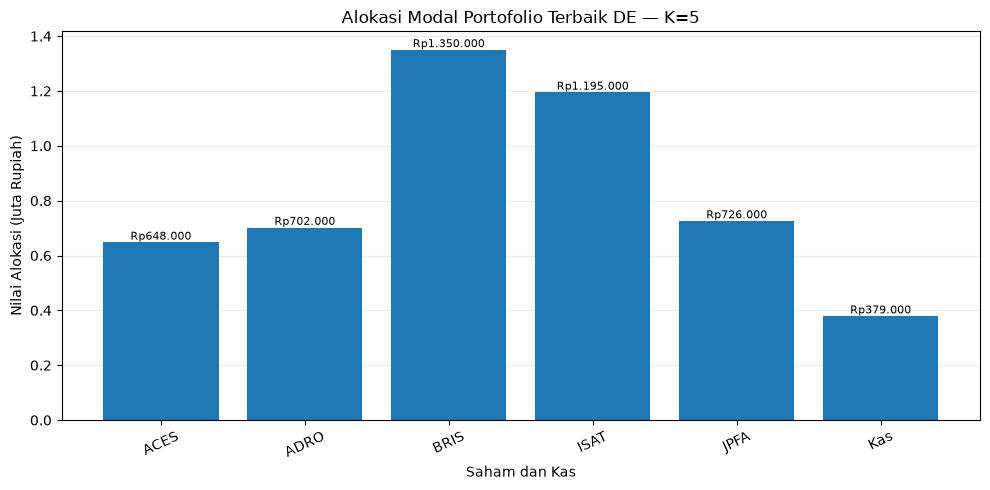


HASIL ALOKASI MODAL TERBAIK DE
K terbaik          : 5
Jumlah saham       : 5 emiten
Expected return    : 31.86% per tahun
Risiko portofolio  : 19.53% per tahun
Dana saham         : Rp4.621.000
Sisa kas           : Rp379.000
File alokasi disimpan: de_ringkasan_alokasi.csv dan de_rincian_saham_lot.csv


In [75]:
# Pilih Alokasi Terbaik Berdasarkan Return Latih yang Layak
ringkasan_alokasi = []
portofolio_terpilih = {}
rincian_seluruh_k = []
for K in KS_TETAP:
    layak = df_tetap[(df_tetap.K == K) & (df_tetap.valid_latih)]
    if layak.empty:
        print(f'K={K}: belum ditemukan solusi layak.')
        continue
    row = layak.sort_values(['return_latih','seed'], ascending=[False, True]).iloc[0]
    seed = int(row.seed)
    pk, hasil = kandidat_tetap[(K,seed)]
    portofolio_terpilih[K] = (pk,hasil)
    biaya = hasil.lots * pk.harga_lot
    total_biaya = float(biaya.sum())
    sisa_kas = float(pk.D - total_biaya)
    assert np.isclose(total_biaya + sisa_kas, pk.D)
    ringkasan_alokasi.append({
        'K Maksimal':K, 'Seed Terbaik':seed, 'Saham Dibeli (Emiten)':int((hasil.lots>0).sum()),
        'Modal (Rp)':pk.D, 'Dana Saham (Rp)':total_biaya, 'Sisa Kas (Rp)':sisa_kas,
        'Kas (% Modal)':sisa_kas/pk.D, 'Expected Return Latih (%/Tahun)':hasil.R,
        'Risiko Latih (%/Tahun)':hasil.sigma, 'Batas Risiko (%/Tahun)':pk.sigma_max,
        'Status':'LAYAK' if hasil.feasible else 'TIDAK LAYAK'
    })
    a = analisis(pk,hasil.lots)
    for i in np.flatnonzero(hasil.lots>0):
        rincian_seluruh_k.append({
            'K Maksimal': K, 'Seed Terbaik':seed, 'Saham':pk.tickers[i],
            'Jumlah Lot':int(hasil.lots[i]), 'Harga per Lot (Rp)':float(pk.harga_lot[i]),
            'Biaya Beli (Rp)':float(biaya[i]), 'Bobot (% Modal)':float(a['w'][i]),
            'Estimasi Return Saham (%/Tahun)':float(pk.mu[i]),
            'Kontribusi Return (Poin Persentase/Tahun)':float(a['R_saham'][i])
        })

df_alokasi = pd.DataFrame(ringkasan_alokasi)
df_rincian = pd.DataFrame(rincian_seluruh_k)
tabel_rapi(df_alokasi,
    persen=['Kas (% Modal)','Expected Return Latih (%/Tahun)','Risiko Latih (%/Tahun)','Batas Risiko (%/Tahun)'],
    rupiah=['Modal (Rp)','Dana Saham (Rp)','Sisa Kas (Rp)'],
    judul='Ringkasan Alokasi Terbaik untuk Setiap K')

# Tabel rincian lengkap pada setiap K.
for K in KS_TETAP:
    pk, hasil = portofolio_terpilih[K]
    rin = df_rincian[df_rincian['K Maksimal']==K].sort_values('Biaya Beli (Rp)',ascending=False)
    tabel_rapi(rin.drop(columns=['K Maksimal','Seed Terbaik']),
        persen=['Bobot (% Modal)','Estimasi Return Saham (%/Tahun)',
                'Kontribusi Return (Poin Persentase/Tahun)'],
        rupiah=['Harga per Lot (Rp)','Biaya Beli (Rp)'],
        judul=f'Rincian Saham dan Lot, K={K} (Seed {hasil.seed})')
    dana_saham=float((hasil.lots*pk.harga_lot).sum())
    sisa=float(pk.D-dana_saham)
    print(f'Ringkasan Modal K={K}: dana saham {rp(dana_saham)} + kas {rp(sisa)} = {rp(pk.D)}')
    print(f'Expected return latih {hasil.R:.2%} per tahun | Risiko latih {hasil.sigma:.2%} '
          f'| Jumlah saham {int((hasil.lots>0).sum())} dari maksimum {K}\n')


# Ringkasan Solusi Terbaik DE dari Seluruh Nilai K

terbaik_de = df_alokasi.loc[
    df_alokasi['Expected Return Latih (%/Tahun)'].idxmax()
]


# GRAFIK ALOKASI MODAL — SOLUSI TERBAIK DE DARI SELURUH K
# 1. Cari K dengan expected return latih tertinggi
K_TERBAIK = max(
    portofolio_terpilih,
    key=lambda k: portofolio_terpilih[k][1].R
)
# 2. Ambil hasil portofolio terbaik pada K tersebut
pk, hasil = portofolio_terpilih[K_TERBAIK]
# 3. Ambil rincian saham yang dibeli
rin = df_rincian[
    df_rincian['K Maksimal'] == K_TERBAIK
]
# 4. Hitung alokasi dana saham dan sisa kas
dana_saham = float((hasil.lots * pk.harga_lot).sum())
sisa_kas = float(pk.D - dana_saham)
komponen = list(rin['Biaya Beli (Rp)']) + [sisa_kas]
label = list(rin['Saham']) + ['Kas']
# 5. Buat grafik alokasi modal
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(label, np.array(komponen) / 1e6)
ax.set(
    title=f'Alokasi Modal Portofolio Terbaik DE — K={K_TERBAIK}',
    xlabel='Saham dan Kas',
    ylabel='Nilai Alokasi (Juta Rupiah)'
)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)

# Tampilkan nominal Rupiah di atas batang
for bar, nominal in zip(bars, komponen):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'Rp{nominal:,.0f}'.replace(',', '.'),
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 6. Tampilkan kesimpulan otomatis
# Ambil nilai risiko dari tabel alokasi terbaik
risiko_portofolio = df_alokasi.loc[
    df_alokasi['K Maksimal'] == K_TERBAIK,
    'Risiko Latih (%/Tahun)'
].iloc[0]
# Tampilkan ringkasan hasil optimasi terbaik DE
print("\nHASIL ALOKASI MODAL TERBAIK DE")
print("=" * 50)
print(f"K terbaik          : {K_TERBAIK}")
print(f"Jumlah saham       : {int((hasil.lots > 0).sum())} emiten")
print(f"Expected return    : {hasil.R:.2%} per tahun")
print(f"Risiko portofolio  : {risiko_portofolio:.2%} per tahun")
print(f"Dana saham         : Rp{dana_saham:,.0f}".replace(',', '.'))
print(f"Sisa kas           : Rp{sisa_kas:,.0f}".replace(',', '.'))
print("=" * 50)

# Ekspor alokasi dalam format yang bisa dipakai untuk laporan.
outdir = ROOT/'hasil'/'csv'; outdir.mkdir(parents=True,exist_ok=True)
df_alokasi.to_csv(outdir/'de_ringkasan_alokasi.csv',index=False)
df_rincian.to_csv(outdir/'de_rincian_saham_lot.csv',index=False)
print('File alokasi disimpan: de_ringkasan_alokasi.csv dan de_rincian_saham_lot.csv')

## 10. Nilai Investasi Berdasarkan Data Latih

**Tujuan:** menerjemahkan expected return tahunan dari hasil DE menjadi gambaran nominal Rupiah.

**Output:** modal, nilai saham awal, kas awal, expected return tahunan, dan **nilai akhir ilustratif 1 tahun (Rp)** untuk setiap K.

In [63]:
proyeksi=[]
for K,(pk,hasil) in portofolio_terpilih.items():
    a=analisis(pk,hasil.lots)
    proyeksi.append({'K Maksimal':K,'Modal (Rp)':pk.D,
       'Dana Saham Awal (Rp)':float((hasil.lots*pk.harga_lot).sum()),
       'Sisa Kas Awal (Rp)':float(pk.D-(hasil.lots*pk.harga_lot).sum()),
       'Expected Return Latih (%/Tahun)':a['R'],
       'Nilai Akhir Ilustratif 1 Tahun (Rp)':pk.D*(1+a['R'])})
tabel_rapi(pd.DataFrame(proyeksi),rupiah=['Modal (Rp)','Dana Saham Awal (Rp)',
    'Sisa Kas Awal (Rp)','Nilai Akhir Ilustratif 1 Tahun (Rp)'],
    persen=['Expected Return Latih (%/Tahun)'],
    judul='Proyeksi Satu Tahun Berdasarkan Return Latih (Bukan Hasil Uji)')

**Proyeksi Satu Tahun Berdasarkan Return Latih (Bukan Hasil Uji)**

K Maksimal,Modal (Rp),Dana Saham Awal (Rp),Sisa Kas Awal (Rp),Expected Return Latih (%/Tahun),Nilai Akhir Ilustratif 1 Tahun (Rp)
2,Rp 5.000.000,Rp 3.787.500,Rp 1.212.500,29.66%,Rp 6.482.881
3,Rp 5.000.000,Rp 3.500.000,Rp 1.500.000,32.23%,Rp 6.611.460
5,Rp 5.000.000,Rp 4.042.500,Rp 957.500,33.95%,Rp 6.697.722
7,Rp 5.000.000,Rp 4.584.500,Rp 415.500,34.09%,Rp 6.704.397
10,Rp 5.000.000,Rp 4.635.500,Rp 364.500,34.13%,Rp 6.706.720


## 11. Pengujian Data Uji: Nilai Portofolio Buy-and-Hold

**Tujuan:** menguji **portofolio terbaik hasil optimasi data latih** pada periode berikutnya tanpa melihat data uji saat memilih saham.

**Grafik:** nilai investasi (juta Rupiah) per hari bursa untuk setiap K, pembanding seluruh kas, dan garis modal awal.

**Tabel:** return total uji (%), return setara tahunan (%), volatilitas uji (% tahunan), penurunan terbesar (*maximum drawdown*, %), nilai saham akhir (Rp), kas akhir (Rp), dan **total nilai akhir (Rp)**.

**Hal yang perlu diperhatikan:** sebuah solusi bisa layak pada data latih tetapi melewati batas volatilitas pada data uji karena kondisi pasar berubah.

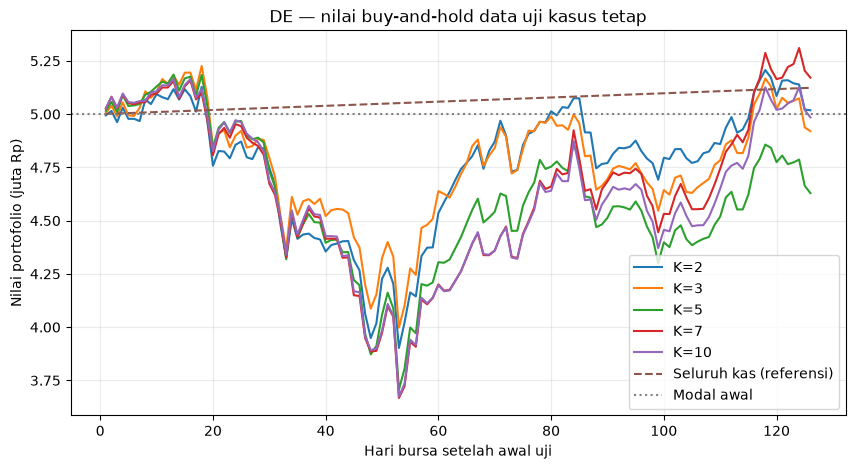

**Hasil Buy-And-Hold di Periode Uji (Portofolio Terbaik Tiap K)**

K Maksimal,Seed Terbaik,Return Total Uji (%),Return Setara Tahunan Uji (%),Volatilitas Uji (%/Tahun),Max Drawdown (%),Nilai Saham Akhir (Rp),Kas Akhir (Rp),Total Nilai Akhir (Rp),Memenuhi Batas Risiko Uji
2,0,0.36%,0.72%,28.46%,-23.90%,Rp 3.300.686,Rp 1.717.389,Rp 5.018.075,False
3,0,-1.60%,-3.19%,29.45%,-23.51%,Rp 3.856.086,Rp 1.064.146,Rp 4.920.232,False
5,0,-7.42%,-14.83%,31.63%,-28.51%,Rp 4.240.861,Rp 388.359,Rp 4.629.220,False
7,10,3.42%,6.85%,31.55%,-28.91%,Rp 5.031.299,Rp 139.871,Rp 5.171.170,False
10,6,-0.31%,-0.62%,31.23%,-28.88%,Rp 4.818.608,Rp 166.001,Rp 4.984.608,False


In [76]:
baris_uji=[]
fig,ax=plt.subplots(figsize=(10,5))
for K,(pk,r) in portofolio_terpilih.items():
    nilai=nilai_uji(pk,r.lots,wdata['return_uji'])
    m=metrik_uji(nilai,pk.D)
    sah,kas_akhir=komponen_akhir(pk,r.lots,wdata['return_uji'])
    baris_uji.append({'K':K,'seed':r.seed,'return_total_uji':m['total'],
      'return_setara_tahun':m['setara_tahun'],'vol_uji':m['vol'],'max_drawdown':m['mdd'],
      'nilai_saham_akhir_Rp':sah,'nilai_kas_akhir_Rp':kas_akhir,'nilai_total_akhir_Rp':nilai[-1],
      'memenuhi_batas_risiko_uji':m['vol']<=pk.sigma_max})
    ax.plot(range(1,len(nilai)+1),nilai/1e6,label=f'K={K}')
T=len(wdata['return_uji'])
ax.plot(range(1,T+1),nilai_kas(config.D_UTAMA,config.RISK_FREE,T)/1e6,'--',label='Seluruh kas (referensi)')
ax.axhline(config.D_UTAMA/1e6,color='gray',ls=':',label='Modal awal')
ax.set(xlabel='Hari bursa setelah awal uji',ylabel='Nilai portofolio (juta Rp)',title='DE — nilai buy-and-hold data uji kasus tetap')
ax.legend();ax.grid(alpha=.25);plt.show()
hasil_uji_rapi=pd.DataFrame(baris_uji).rename(columns={
    'K':'K Maksimal','seed':'Seed Terbaik','return_total_uji':'Return Total Uji (%)',
    'return_setara_tahun':'Return Setara Tahunan Uji (%)','vol_uji':'Volatilitas Uji (%/Tahun)',
    'max_drawdown':'Max Drawdown (%)','nilai_saham_akhir_Rp':'Nilai Saham Akhir (Rp)',
    'nilai_kas_akhir_Rp':'Kas Akhir (Rp)','nilai_total_akhir_Rp':'Total Nilai Akhir (Rp)',
    'memenuhi_batas_risiko_uji':'Memenuhi Batas Risiko Uji'})
tabel_rapi(hasil_uji_rapi,
    persen=['Return Total Uji (%)','Return Setara Tahunan Uji (%)',
            'Volatilitas Uji (%/Tahun)','Max Drawdown (%)'],
    rupiah=['Nilai Saham Akhir (Rp)','Kas Akhir (Rp)','Total Nilai Akhir (Rp)'],
    judul='Hasil Buy-And-Hold di Periode Uji (Portofolio Terbaik Tiap K)')

## 12. Eksperimen Walk-Forward

**Tujuan:** mengulang proses optimasi dan pengujian pada tiga periode berbeda agar kesimpulan tidak bergantung pada satu kondisi pasar.

Untuk setiap jendela dijalankan seluruh nilai K dan 10 seed. Tiap run memiliki anggaran 20.000 evaluasi fitness pada mode `lengkap`.

**Output:** total run, progres per kombinasi jendela–K, dan CSV hasil mentah.

In [65]:
MODE = 'lengkap'   # 'cek' atau 'lengkap'
WINDOWS = ['jendela_1', 'jendela_2', 'jendela_3'] if MODE == 'lengkap' else ['jendela_1']
KS = [2, 3, 5, 7, 10] if MODE == 'lengkap' else [5]
SEEDS = range(10) if MODE == 'lengkap' else range(1)
BUDGET = 20_000 if MODE == 'lengkap' else 1000
print('Total run:', len(WINDOWS)*len(KS)*len(SEEDS))

Total run: 150


In [66]:
records=[]
portofolio=[]
histories=[]
started=time.perf_counter()
for nama in WINDOWS:
    wdata=muat_jendela(nama)
    for K in KS:
        problem=buat_problem(wdata,K=K)
        for seed in SEEDS:
            result=de.run(problem,budget=BUDGET,seed=seed)
            lots,bobot,kas=decode(result.x,problem)
            nilai=nilai_uji(problem,result.lots,wdata['return_uji'])
            out=metrik_uji(nilai,problem.D)
            # Periode uji bukan pelatihan: evaluasi risiko aktual, bukan constraint keras saat mencari.
            row=dict(algoritma='DE',jendela=nama,K=K,seed=seed,modal=problem.D,
                     sigma_max=problem.sigma_max,return_latih=result.R,risiko_latih=result.sigma,
                     valid_latih=bool(result.feasible),n_eval=result.n_eval,
                     eval_terbaik=result.n_eval_best,waktu_detik=result.seconds,
                     jumlah_saham=int((lots>0).sum()),porsi_kas=float(kas),
                     return_uji_total=out['total'],return_uji_tahunan=out['setara_tahun'],
                     risiko_uji=out['vol'],max_drawdown=out['mdd'],
                     risiko_uji_memenuhi=bool(out['vol'] <= problem.sigma_max),
                     tanggal_uji_awal=wdata['tanggal_uji_awal'],tanggal_uji_akhir=wdata['tanggal_uji_akhir'])
            records.append(row)
            portofolio.append(dict(jendela=nama,K=K,seed=seed,
                                  lots=';'.join(map(str,lots)),tickers=';'.join(problem.tickers)))
            histories.extend(dict(jendela=nama,K=K,seed=seed,n_eval=n,return_terbaik=R)
                             for n,R in result.history)
        print(f'{nama} K={K}: {len(SEEDS)} seed selesai')
df=pd.DataFrame(records)
outdir=ROOT/'hasil'/'csv';outdir.mkdir(parents=True,exist_ok=True)
df.to_csv(outdir/'de_walkforward.csv',index=False)
pd.DataFrame(portofolio).to_csv(outdir/'de_portofolio_lot.csv',index=False)
pd.DataFrame(histories).to_csv(outdir/'de_konvergensi.csv',index=False)
print('Selesai:',len(df),'run | waktu total:',round(time.perf_counter()-started,1),'detik')
print('CSV tersimpan ke',outdir)
print('Cuplikan 5 run pertama dari tabel hasil mentah:')
cuplikan=df.head().rename(columns={'algoritma':'Algoritma','jendela':'Jendela','K':'K Maksimal',
   'seed':'Seed','return_latih':'Expected Return Latih (%/Tahun)',
   'risiko_latih':'Risiko Latih (%/Tahun)','return_uji_tahunan':'Return Uji (%/Tahun)',
   'porsi_kas':'Kas (% Modal)','jumlah_saham':'Jumlah Saham','valid_latih':'Layak di Latih'})
kolom=['Algoritma','Jendela','K Maksimal','Seed','Expected Return Latih (%/Tahun)',
       'Risiko Latih (%/Tahun)','Layak di Latih','Jumlah Saham','Kas (% Modal)',
       'Return Uji (%/Tahun)']
tabel_rapi(cuplikan[kolom], persen=['Expected Return Latih (%/Tahun)',
           'Risiko Latih (%/Tahun)','Kas (% Modal)','Return Uji (%/Tahun)'],
           judul='Contoh Data Mentah (5 dari seluruh run)')

jendela_1 K=2: 10 seed selesai
jendela_1 K=3: 10 seed selesai
jendela_1 K=5: 10 seed selesai
jendela_1 K=7: 10 seed selesai
jendela_1 K=10: 10 seed selesai
jendela_2 K=2: 10 seed selesai
jendela_2 K=3: 10 seed selesai
jendela_2 K=5: 10 seed selesai
jendela_2 K=7: 10 seed selesai
jendela_2 K=10: 10 seed selesai
jendela_3 K=2: 10 seed selesai
jendela_3 K=3: 10 seed selesai
jendela_3 K=5: 10 seed selesai
jendela_3 K=7: 10 seed selesai
jendela_3 K=10: 10 seed selesai
Selesai: 150 run | waktu total: 55.1 detik
CSV tersimpan ke c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\hasil\csv
Cuplikan 5 run pertama dari tabel hasil mentah:


**Contoh Data Mentah (5 dari seluruh run)**

Algoritma,Jendela,K Maksimal,Seed,Expected Return Latih (%/Tahun),Risiko Latih (%/Tahun),Layak di Latih,Jumlah Saham,Kas (% Modal),Return Uji (%/Tahun)
DE,jendela_1,2,0,33.98%,19.93%,True,2,30.40%,5.05%
DE,jendela_1,2,1,33.98%,19.93%,True,2,30.40%,5.05%
DE,jendela_1,2,2,33.98%,19.93%,True,2,30.40%,5.05%
DE,jendela_1,2,3,33.98%,19.93%,True,2,30.40%,5.05%
DE,jendela_1,2,4,33.98%,19.93%,True,2,30.40%,5.05%


## 13. Rekap Walk-Forward Per Jendela dan K

**Tujuan:** merangkum seluruh percobaan menjadi tabel yang mudah dibandingkan.

**Output:** jumlah run, median expected return latih (% per tahun), simpangan baku (%), kelayakan latih (% run), median waktu (detik), median kas (% modal), jumlah saham aktual, median return tahunan uji (%), volatilitas uji (%), dan persentase run yang memenuhi batas risiko uji.

In [67]:
rekap=(df.groupby(['jendela','K']).agg(
    n_run=('return_latih','size'),
    median_return_latih=('return_latih','median'),
    std_return_latih=('return_latih','std'),
    tingkat_kelayakan=('valid_latih','mean'),
    median_waktu=('waktu_detik','median'),
    median_kas=('porsi_kas','median'),
    median_jumlah_saham=('jumlah_saham','median'),
    median_return_uji=('return_uji_tahunan','median'),
    median_vol_uji=('risiko_uji','median'),
    proporsi_memenuhi_risiko_uji=('risiko_uji_memenuhi','mean')).reset_index())
rekap_rapi=rekap.rename(columns={'jendela':'Jendela','K':'K Maksimal','n_run':'Jumlah Run',
   'median_return_latih':'Median Return Latih (%/Tahun)','std_return_latih':'Simpangan Baku Return Latih (%)',
   'tingkat_kelayakan':'Kelayakan Latih (% Run)','median_waktu':'Median Waktu (Detik)',
   'median_kas':'Median Kas (% Modal)','median_jumlah_saham':'Median Jumlah Saham',
   'median_return_uji':'Median Return Uji (%/Tahun)','median_vol_uji':'Median Volatilitas Uji (%/Tahun)',
   'proporsi_memenuhi_risiko_uji':'Kepatuhan Risiko Uji (% Run)'})
tabel_rapi(rekap_rapi,persen=['Median Return Latih (%/Tahun)','Simpangan Baku Return Latih (%)',
    'Kelayakan Latih (% Run)','Median Kas (% Modal)','Median Return Uji (%/Tahun)',
    'Median Volatilitas Uji (%/Tahun)','Kepatuhan Risiko Uji (% Run)'],
    desimal=['Median Waktu (Detik)','Median Jumlah Saham'],
    judul='Rekap Walk-Forward DE: Ringkasan Statistik Per Jendela dan K Maksimal')
rekap.to_csv(outdir/'de_rekap_walkforward.csv',index=False)

**Rekap Walk-Forward DE: Ringkasan Statistik Per Jendela dan K Maksimal**

Jendela,K Maksimal,Jumlah Run,Median Return Latih (%/Tahun),Simpangan Baku Return Latih (%),Kelayakan Latih (% Run),Median Waktu (Detik),Median Kas (% Modal),Median Jumlah Saham,Median Return Uji (%/Tahun),Median Volatilitas Uji (%/Tahun),Kepatuhan Risiko Uji (% Run)
jendela_1,2,10,33.98%,0.00%,100.00%,0.343,30.40%,2.000,5.05%,13.39%,100.00%
jendela_1,3,10,37.75%,0.76%,100.00%,0.342,9.55%,3.000,11.90%,18.13%,100.00%
jendela_1,5,10,43.62%,0.36%,100.00%,0.359,8.15%,5.000,4.50%,17.05%,100.00%
jendela_1,7,10,43.51%,0.36%,100.00%,0.428,6.88%,6.000,13.60%,16.37%,100.00%
jendela_1,10,10,43.47%,0.18%,100.00%,0.397,7.17%,6.000,12.18%,16.43%,100.00%
jendela_2,2,10,30.92%,1.04%,100.00%,0.322,19.45%,2.000,-14.66%,22.76%,0.00%
jendela_2,3,10,36.02%,0.00%,100.00%,0.315,18.66%,3.000,-16.83%,21.01%,0.00%
jendela_2,5,10,37.95%,0.23%,100.00%,0.317,7.13%,5.000,-15.45%,20.31%,30.00%
jendela_2,7,10,37.21%,0.31%,100.00%,0.401,6.60%,6.000,-10.43%,18.78%,100.00%
jendela_2,10,10,37.14%,0.25%,100.00%,0.395,6.18%,7.000,-12.98%,19.18%,100.00%


## 14. Grafik Perbandingan K dan Periode

**Tujuan:** melihat perubahan kualitas hasil DE dari satu nilai K ke nilai K lain serta dari satu periode pasar ke periode berikutnya.

- **Grafik kiri/pertama:** median expected return **data latih** (% per tahun).
- **Grafik kanan/kedua:** median return tahunan pada **data uji** (% per tahun).

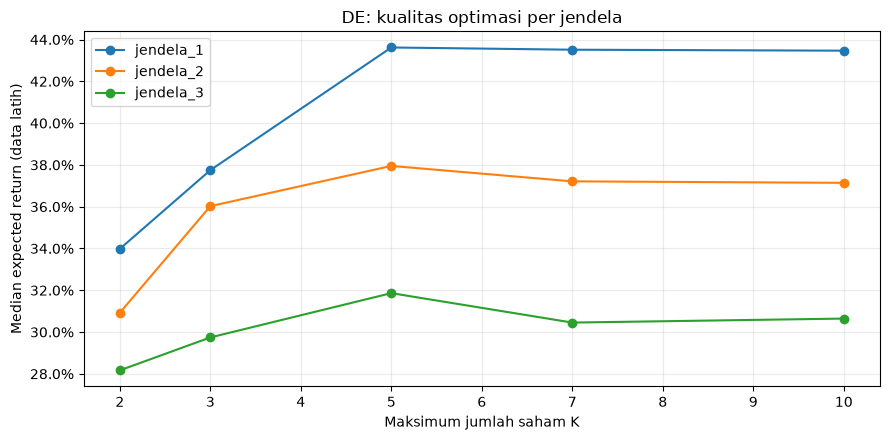

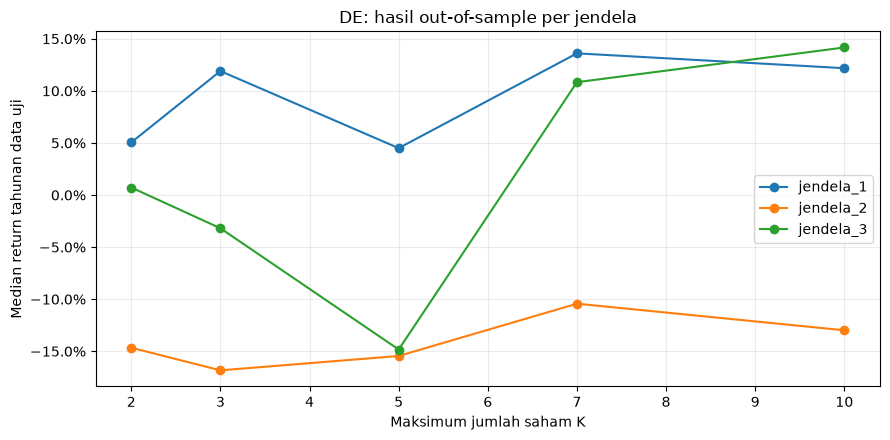

In [68]:
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g['K'],g['median_return_latih'],marker='o',label=nama)
ax.set(xlabel='Maksimum jumlah saham K',ylabel='Median expected return (data latih)',title='DE: kualitas optimasi per jendela')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g['K'],g['median_return_uji'],marker='o',label=nama)
ax.set(xlabel='Maksimum jumlah saham K',ylabel='Median return tahunan data uji',title='DE: hasil out-of-sample per jendela')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()

## 15. Diagnostik: Hubungan Latih-Uji dan Waktu Komputasi

**Tujuan:** mengamati apakah return latih yang lebih tinggi berkaitan dengan return uji, serta melihat biaya komputasi DE.

**Output:** scatter plot return latih vs return uji (persen per tahun), grafik median waktu per run (detik), dan jumlah run layak pada data latih serta data uji.

**Catatan:** titik-titik scatter merupakan hasil seed yang diuji pada data uji yang sama dalam satu jendela, sehingga bukan 150 periode pasar independen.

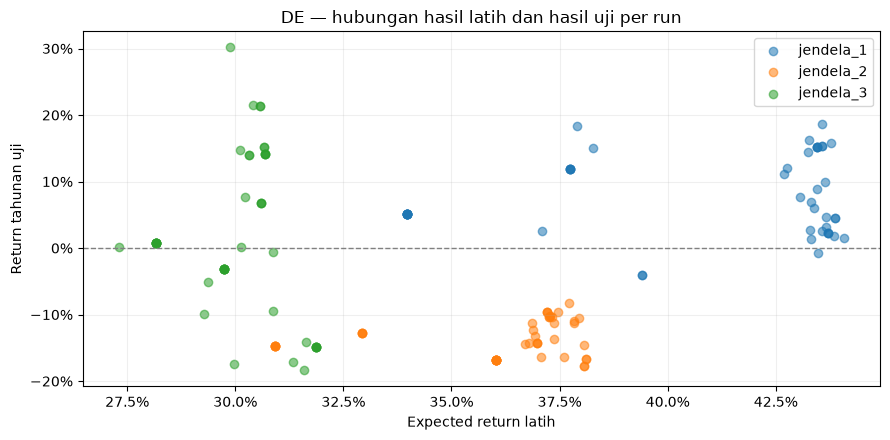

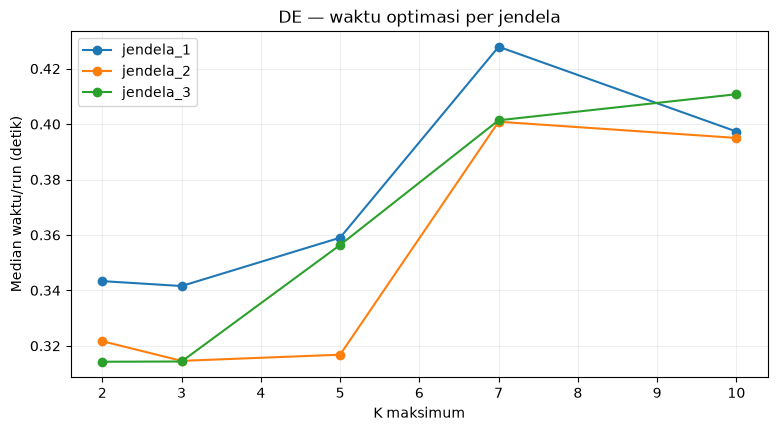

Jumlah run latih feasible: 150 dari 150
Jumlah run risiko UJI memenuhi: 73 dari 150


In [69]:
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in df.groupby('jendela'):
    ax.scatter(g['return_latih'],g['return_uji_tahunan'],alpha=.55,label=nama)
ax.axhline(0,color='gray',ls='--',lw=1)
ax.set(xlabel='Expected return latih',ylabel='Return tahunan uji',title='DE — hubungan hasil latih dan hasil uji per run')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0));ax.grid(alpha=.2);ax.legend();plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
for nama,g in rekap.groupby('jendela'):
    ax.plot(g.K,g.median_waktu,marker='o',label=nama)
ax.set(xlabel='K maksimum',ylabel='Median waktu/run (detik)',title='DE — waktu optimasi per jendela')
ax.grid(alpha=.2);ax.legend();plt.show()
print('Jumlah run latih feasible:',int(df.valid_latih.sum()),'dari',len(df))
print('Jumlah run risiko UJI memenuhi:',int(df.risiko_uji_memenuhi.sum()),'dari',len(df))

## 16. Pemeriksaan Akhir dan Kesimpulan

**Tujuan:** memastikan jumlah run benar, anggaran evaluasi konsisten, jumlah saham tidak melampaui K, dan tidak ada nilai evaluasi utama yang kosong.

Bagian ini juga menampilkan **kesimpulan otomatis singkat** dari eksperimen DE.

In [70]:
assert (df['n_eval']==BUDGET).all()
assert (df['jumlah_saham']<=df['K']).all()
assert df[['return_latih','risiko_latih','return_uji_total','risiko_uji']].notna().all().all()
print('Pemeriksaan dasar lulus. Tingkat kelayakan latih:',df.valid_latih.mean())
assert len(df)==len(WINDOWS)*len(KS)*len(SEEDS)
assert (df['waktu_detik']>=0).all()
print('Selesai. File hasil tersedia di:',outdir)
print('CSV kasus tetap dan walk-forward sudah diekspor.')

Pemeriksaan dasar lulus. Tingkat kelayakan latih: 1.0
Selesai. File hasil tersedia di: c:\Users\LENOVO\Downloads\Projek ETS SC\GitHub\OptimasiPortofolioSaham\hasil\csv
CSV kasus tetap dan walk-forward sudah diekspor.


## 17. Rangkuman

**Bagian ini memusatkan hasil:** *alokasi modal terbaik menurut DE untuk masing-masing K* dan *bagaimana hasilnya ketika diuji*. Semua nilai diperoleh dari sel sebelumnya.

In [71]:
tabel_rapi(df_alokasi[['K Maksimal','Seed Terbaik','Saham Dibeli (Emiten)','Dana Saham (Rp)',
  'Sisa Kas (Rp)','Expected Return Latih (%/Tahun)','Risiko Latih (%/Tahun)','Status']],
  rupiah=['Dana Saham (Rp)','Sisa Kas (Rp)'],
  persen=['Expected Return Latih (%/Tahun)','Risiko Latih (%/Tahun)'],
  judul='Alokasi Dana Terbaik Menurut DE Pada Data Latih')
tabel_rapi(hasil_uji_rapi[['K Maksimal','Return Total Uji (%)','Return Setara Tahunan Uji (%)',
  'Volatilitas Uji (%/Tahun)','Max Drawdown (%)','Total Nilai Akhir (Rp)']],
  rupiah=['Total Nilai Akhir (Rp)'],
  persen=['Return Total Uji (%)','Return Setara Tahunan Uji (%)',
          'Volatilitas Uji (%/Tahun)','Max Drawdown (%)'],
  judul='Kinerja Portofolio Terpilih Pada Data Uji')
print('CATATAN: tabel pertama dipilih berdasarkan data latih; tabel kedua menguji hasilnya pada periode berbeda.')
print('Rincian semua saham dan lot tersedia di Bagian 9 dan file hasil/csv/de_rincian_saham_lot.csv.')

**Alokasi Dana Terbaik Menurut DE Pada Data Latih**

K Maksimal,Seed Terbaik,Saham Dibeli (Emiten),Dana Saham (Rp),Sisa Kas (Rp),Expected Return Latih (%/Tahun),Risiko Latih (%/Tahun),Status
2,7,2,Rp 3.787.500,Rp 1.212.500,29.66%,23.77%,LAYAK
3,0,3,Rp 3.500.000,Rp 1.500.000,32.23%,23.85%,LAYAK
5,6,5,Rp 4.042.500,Rp 957.500,33.95%,23.80%,LAYAK
7,13,7,Rp 4.584.500,Rp 415.500,34.09%,23.88%,LAYAK
10,29,7,Rp 4.635.500,Rp 364.500,34.13%,23.88%,LAYAK


**Kinerja Portofolio Terpilih Pada Data Uji**

K Maksimal,Return Total Uji (%),Return Setara Tahunan Uji (%),Volatilitas Uji (%/Tahun),Max Drawdown (%),Total Nilai Akhir (Rp)
2,-9.17%,-9.67%,23.36%,-20.53%,Rp 4.541.291
3,9.57%,10.09%,24.64%,-16.14%,Rp 5.478.374
5,6.41%,6.76%,25.14%,-17.23%,Rp 5.320.581
7,3.45%,3.64%,26.41%,-21.46%,Rp 5.172.536
10,4.24%,4.47%,26.37%,-21.45%,Rp 5.211.997


CATATAN: tabel pertama dipilih berdasarkan data latih; tabel kedua menguji hasilnya pada periode berbeda.
Rincian semua saham dan lot tersedia di Bagian 9 dan file hasil/csv/de_rincian_saham_lot.csv.
